In [1]:
import os #organizador de pasta
import numpy as np #estruturação dos dados
import matplotlib.pyplot as plt #plot gráfico
import seaborn as sns #plot gráfico
from PIL import Image #visualização de img
import pandas as pd #estruturação dos dados
from util import meus_uteis, timeProcess
import joblib #convertendo imagens em valores numéricos .gz
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis

Foram criadas 3 pastas a partir das imagens originais. Uma das pastas recebeu as imagens sem marcador, outra pasta recebeu as imagens marcadas sem rótulo e a terceira pasta recebeu as imagens marcadas com os rótulos. Nesse notebook, estamos trabalhando com 40 (iniciais) imagens marcadas com os rótulos.

In [5]:
novas_imagens = "./data/realcadas_verde_HBMC/"
img_key = 0 #Chave da primeira imagem

lista_novas_img = os.listdir(novas_imagens) #listando as figuras salvas no diretório
len(lista_novas_img) #quantidade de imagens
#lista_novas_img

31

Visualização das imagens (x): Melhor resolução 300x300

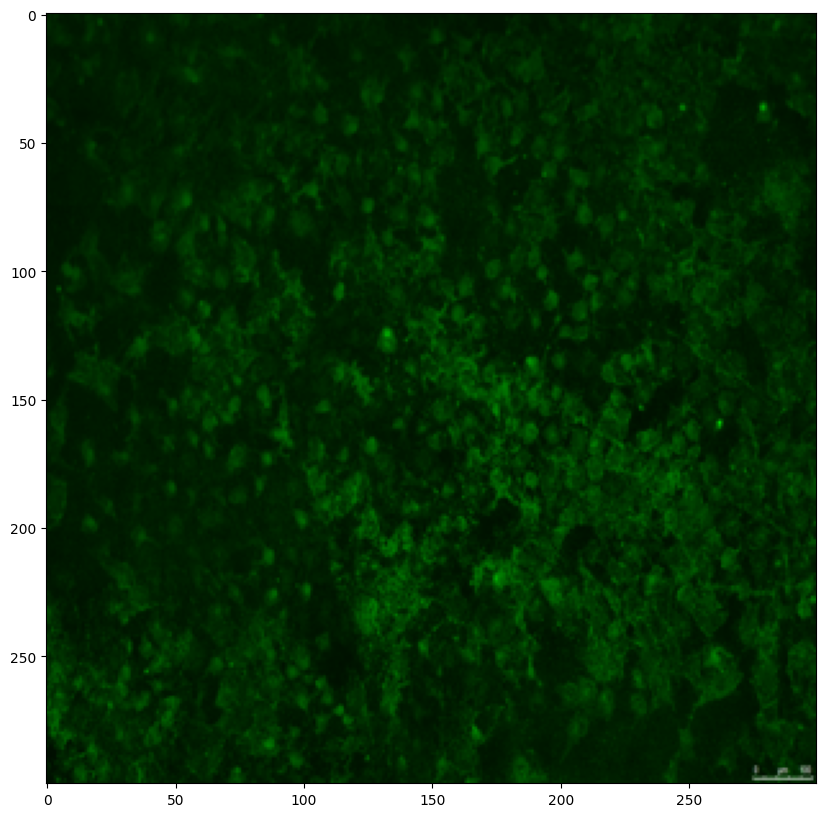

In [6]:
#testando as imagens
resize_img = (300,300) #tamanho da imagem
image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

In [10]:
!pip install opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 8.3 MB/s  0:00:08m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 9.3 MB/s  0:00:01 eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.23.5
    Uninstalling numpy-1.23.5:
      Successfully uninstalled numpy-1.23.5━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [opencv-python]0m [opencv-python]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scipy 1.11.3 requires numpy<1.28.0,>=1.21.6, but you have numpy 2.2.6 which is incompatible.
tensorflow 2.12.0 requires numpy<1.24,>=1.22, but you have numpy 2.2.6 which is incompatible.


In [11]:
import os
import cv2
import numpy as np

ImportError: libGL.so.1: cannot open shared object file: No such file or directory

In [6]:
# # Caminho para a pasta com as imagens TIFF originais
# novas_imagens = '/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_julia_quantificacao/imagens linhagem HBMEC/linhagem_HBMEC'
# lista_novas_img = os.listdir(novas_imagens)

# # Criar pasta para salvar as imagens realçadas
# saida_dir = os.path.join(novas_imagens, 'realcadas_verde')
# os.makedirs(saida_dir, exist_ok=True)

# # Configurar CLAHE
# clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# # Processar imagens .tif
# for nome_arquivo in lista_novas_img:
#     if nome_arquivo.lower().endswith('.tif'):
#         caminho_img = os.path.join(novas_imagens, nome_arquivo)

#         # Carregar imagem
#         img = cv2.imread(caminho_img)

#         if img is None:
#             print(f"Erro ao carregar: {nome_arquivo}")
#             continue

#         # Realce do canal verde
#         canal_verde = img[:, :, 1]
#         verde_realcado = clahe.apply(canal_verde)
#         img[:, :, 1] = verde_realcado

#         # Salvar nova imagem
#         caminho_saida = os.path.join(saida_dir, f"realcada_{nome_arquivo}")
#         cv2.imwrite(caminho_saida, img)
#         print(f"Salvo: {caminho_saida}")

# print("✅ Todas as imagens foram processadas com sucesso!")

In [7]:
novas_imagens = '/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_julia_quantificacao/imagens linhagem HBMEC/linhagem_HBMEC/realcadas_verde' #diretório
img_key = 0 #Chave da primeira imagem

lista_novas_img = os.listdir(novas_imagens) #listando as figuras salvas no diretório
len(lista_novas_img) #quantidade de imagens
#lista_novas_img

31

#1. Original orientation of the image.

In [8]:
# y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img] #cortando informações da imagem
# y_rotulo_imagem = [(n.split('.tif')[0]) for n in y_rotulo_imagem]
# y_rotulo_imagem = y_rotulo_imagem
# print(len(y_rotulo_imagem)) #verificando o numero de rótulos corresponde o numero de imagens
# print(y_rotulo_imagem)

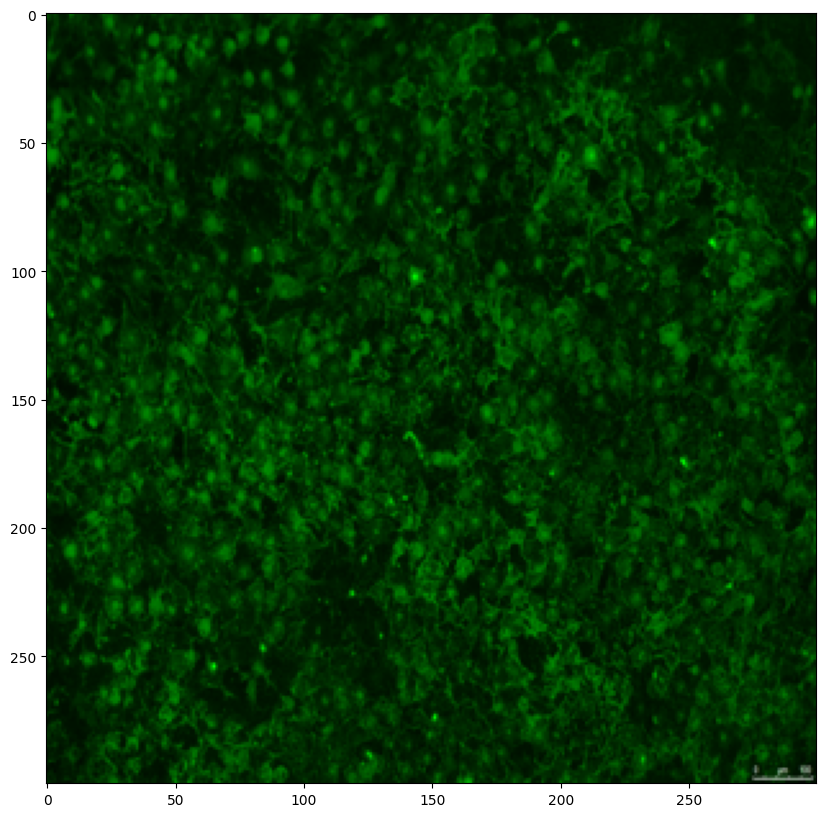

In [9]:
#testando as imagens
resize_img = (300,300) #tamanho da imagem
image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

Formatting all images that are saved in the directory into an array

In [10]:
lista_imagens_camp_claro = [] #lista vazia onde vai ser armazenado os dados
for file in lista_novas_img[:]:  #laço pra salvar todas as imagens
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test) #abrir a imagem
    img = img.resize(resize_img) #formatando em 300x300
    img = np.asarray(img)[:,:,:3] #formatando em array
    lista_imagens_camp_claro.append(img)  #adicionando cada imagem
np.asarray(lista_imagens_camp_claro).shape #verificando quantas imagens foram salvas em qual tamnho e camadas

(31, 300, 300, 3)

In [11]:
data = timeProcess()[1]
#joblib.dump(np.asarray(lista_imagens_camp_claro), '/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_BAELB/img.gz_campo_claro/lista_img_100_resized_regre_campo_claro_'+data+'.gz')

#2. Saving inverted images from left to right

label (80 - doubled) - dobrando o numero de rótulos

In [12]:
# #dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
# y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
# len(y_rotulo_soma)

In [13]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(62, 300, 300, 3)

#3. Saving inverted images from bottom to top

y = label (120 - doubled)

In [14]:
# #dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
# y_rotulo_soma += y_rotulo_imagem
# len(y_rotulo_soma)

In [15]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(93, 300, 300, 3)

# 4. Saving the images flipped upside down.

label (160 - doubled) - dobrando o numero de rótulos

In [16]:
# y_rotulo_soma += y_rotulo_imagem
# len(y_rotulo_soma)

In [17]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(124, 300, 300, 3)

Salvando em uma lista as imagens em diferentes orientações.

In [18]:
data = timeProcess()[1]
joblib.dump(np.asarray(lista_imagens_camp_claro), '/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_julia_quantificacao/lista de imagens e rótulos HBMEC/realçadas/lista_imagem_100_resized_regre_HBMEC_realce_'+data+'.gz')

['/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_julia_quantificacao/lista de imagens e rótulos HBMEC/realçadas/lista_imagem_100_resized_regre_HBMEC_realce_2025-7-1.gz']

In [19]:
#joblib.dump(np.asarray(y_rotulo_soma), '/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_julia_quantificacao/lista de imagens e rótulos - rosetas like/listas imagens e rótulos roseta like/lista_rotulo_100_resized_regre_balb-roseta_'+data+'.gz')

#TESTE

In [20]:
# y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img] #cortando informações da imagem
# y_rotulo_imagem = [(n.split('.tif')[0]) for n in y_rotulo_imagem]
# y_rotulo_imagem = y_rotulo_imagem
# print(len(y_rotulo_imagem)) #verificando o numero de rótulos corresponde o numero de imagens
# print(y_rotulo_imagem)

In [21]:
import cv2


In [22]:
def rotacionar_imagem(img_np, angulo):
    """Roda a imagem em torno do centro com o ângulo especificado."""
    h, w = img_np.shape[:2]
    centro = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(centro, angulo, 1.0)
    img_rotacionada = cv2.warpAffine(img_np, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)
    return img_rotacionada

In [23]:
lista_imagens_camp_claro = []

for file in lista_novas_img:
    image_test = novas_imagens + '/' + file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img_np = np.asarray(img)[:, :, :3]

    # Gera imagens rotacionadas
    for angulo in [45, 90, 180, 360]:
        img_rot = rotacionar_imagem(img_np, angulo)
        lista_imagens_camp_claro.append(img_rot)

print(np.asarray(lista_imagens_camp_claro).shape)

(124, 300, 300, 3)


In [24]:
joblib.dump(np.asarray(lista_imagens_camp_claro), '/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_julia_quantificacao/lista de imagens e rótulos HBMEC/realçadas/lista_imagem_angulacoes_HBMEC_realce_'+data+'.gz')

['/content/drive/MyDrive/Projeto PEP Julia/teste/imagens_julia_quantificacao/lista de imagens e rótulos HBMEC/realçadas/lista_imagem_angulacoes_HBMEC_realce_2025-7-1.gz']